# Qwen2-VL-7B-Instruct: per-instance error attribution for the field experiment

The [field experiment](../run_field_scripts.sh) sweeps an added white border
("field") around each benchmark image and compares it against two controls
built from the *same* underlying image at *the same* effective resolution
(`src/utils.py:build_field_images`):

- **field** - original embedded in a larger white-bordered canvas,
- **resized** - the plain original downscaled by the coefficient the field
  image experiences during preprocessing (isolates content downscaling from
  the added-border effect),
- **bicubic** - `resized` scaled back up to the original resolution
  (detail loss without a size change).

This mirrors [`llava_error_attribution.ipynb`](llava_error_attribution.ipynb)
but for Qwen2-VL, whose vision pipeline works fundamentally differently from
LLaVA's fixed 336x336 CLIP-ViT crop: Qwen resizes each image to (near) its
*native* resolution, rounded to the nearest 28px (`patch_size=14 x
merge_size=2`) multiple, so ordinarily very little content resolution is lost
before the vision tower ever sees it. But that native-resolution processing
still has a hard limit - the image processor's `min_pixels`/`max_pixels`
config caps the vision token count per image (16,384 tokens for
`Qwen/Qwen2-VL-7B-Instruct`'s published defaults). The field experiment's
white border inflates the canvas area by `(1 + field%)^2`, so at large field
values the bordered canvas can blow past that cap even when the original,
unbordered image never would - forcing Qwen's own `smart_resize` to rescale
the image far more aggressively than its ordinary 28px-rounding behavior. This
notebook:

1. scores field/resized/bicubic like `parse_field_results.py` (aggregate
   accuracy per benchmark),
2. quantifies **how often the field variant exceeds Qwen's vision token
   budget**, and how much more severely such instances get downscaled versus
   Qwen's usual near-native-resolution behavior,
3. attributes each previously-correct instance's fate as the border grows
   (border-specific failure vs. shared resolution-loss failure vs. robust),
   the same four-way split as the LLaVA notebook,
4. runs **CKA** between baseline and corrupted-condition activations for the
   hardest failure patterns (instances wrong under all three variants; and
   instances that flip correct -> wrong -> correct again), and
5. visualizes **attention maps** for DocVQA examples representing distinct
   degradation patterns - one where the field variant got clipped by the
   vision token budget, one where it didn't.

## Setup

In [1]:
import sys
from pathlib import Path

project_root = Path().resolve().parent  # notebooks/ -> project root
sys.path.insert(0, str(project_root))

## Score (or reuse already-scored) field / resized / bicubic results

Reuses the exact scoring from `src/parse_field_results.py` (now generalized to
take a `model`/`model_short` pair rather than hardcoding LLaVA), which itself
reuses the rule-based scorer in `src/parse_results.py`. field=0 (no
transformation at all) predates the field/resized/bicubic naming split and
lives only under `results_old/`; the sweep (0.5-5) lives under `results/`.

In [2]:
import json
import math

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.parse_field_results import score_field_results, FIELD_VALUES, VARIANTS

pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 120)

MODEL = "Qwen_Qwen2-VL-7B-Instruct"
MODEL_SHORT = "Qwen2-VL-7B-Instruct"
MODEL_HF_NAME = "Qwen/Qwen2-VL-7B-Instruct"

In [3]:
RESULTS_DIR = project_root / "results"
RESULTS_OLD_DIR = project_root / "results_old"
SCORED_DIR = project_root / "results_scored_field"

field_df = score_field_results(RESULTS_DIR, RESULTS_OLD_DIR, SCORED_DIR, model=MODEL, model_short=MODEL_SHORT)

NEW_VALUES = [v for v in FIELD_VALUES if v != "0"]
BENCHMARKS = sorted(p.name for p in (RESULTS_DIR / MODEL).iterdir() if p.is_dir())
print(f"{len(BENCHMARKS)} benchmarks, field values {NEW_VALUES} (+ shared baseline 0)")

15 benchmarks, field values ['0.5', '1', '2', '3', '4', '5'] (+ shared baseline 0)


## Aggregate accuracy: field vs. resized vs. bicubic

Restricted to **reliably-parseable** benchmarks only, for the same reason as
the LLaVA notebook: `MMVet`/`CharXiv`/`MathVerse` are graded with heuristic
substring containment (a rough lower-bound proxy, not real correctness), so
they're excluded here to keep the table honest.

In [4]:
from src.parse_results import (
    MCQ_BENCHMARKS, SHORT_ANSWER_BENCHMARKS, YESNO_BENCHMARKS,
    OPEN_ENDED_BENCHMARKS, MIXED_BENCHMARKS,
)

RELIABLE_BENCHMARKS = sorted((MCQ_BENCHMARKS | SHORT_ANSWER_BENCHMARKS | YESNO_BENCHMARKS) & set(BENCHMARKS))
UNRELIABLE_BENCHMARKS = sorted((OPEN_ENDED_BENCHMARKS | MIXED_BENCHMARKS) & set(BENCHMARKS))

print(f"{len(RELIABLE_BENCHMARKS)} reliably-parseable benchmarks: {RELIABLE_BENCHMARKS}")
print(f"{len(UNRELIABLE_BENCHMARKS)} excluded (heuristic substring-containment eval_method): {UNRELIABLE_BENCHMARKS}")

reliable_df = field_df[field_df["benchmark"].isin(RELIABLE_BENCHMARKS)]

12 reliably-parseable benchmarks: ['CVBench', 'ChartQA', 'DocVQA', 'GQA', 'HRBench', 'InfographicVQA', 'MMERealWorldLite', 'MMEval', 'MMStar', 'TextVQA', 'VQAv2', 'VStarBench']
3 excluded (heuristic substring-containment eval_method): ['CharXiv', 'MMVet', 'MathVerse']


### Mean accuracy across reliably-parseable benchmarks, by variant x field value

In [5]:
mean_accuracy = (
    reliable_df.pivot_table(index="variant", columns="field_value", values="accuracy", aggfunc="mean")
    .reindex(VARIANTS)
    * 100
).round(1)
mean_accuracy

field_value,0.0,0.5,1.0,2.0,3.0,4.0,5.0
variant,,,,,,,
field,70.4,70.8,70.7,68.4,67.3,65.9,63.1
resized,70.4,71.1,70.9,69.6,68.9,67.9,66.1
bicubic,70.4,71.0,70.9,70.5,69.7,69.5,69.8


### Accuracy per benchmark, per input variation

In [6]:
for variant in VARIANTS:
    vdf = reliable_df[reliable_df["variant"] == variant]
    table = (vdf.pivot(index="benchmark", columns="field_value", values="accuracy") * 100).round(1)
    print(f"=== {variant} ===")
    print(table)
    print()

=== field ===
field_value        0.0   0.5   1.0   2.0   3.0   4.0   5.0
benchmark                                                 
CVBench           77.0  74.9  76.9  73.5  71.0  68.5  62.5
ChartQA           79.0  78.5  77.5  79.0  80.0  77.0  77.0
DocVQA            88.0  86.5  87.5  86.5  85.5  85.0  79.0
GQA               64.0  66.5  66.5  64.5  64.5  60.0  62.5
HRBench           61.5  59.5  58.0  49.5  45.0  46.0  44.0
InfographicVQA    72.5  73.0  72.0  71.0  68.5  66.5  57.5
MMERealWorldLite  47.0  44.0  42.0  41.0  40.5  41.0  37.5
MMEval            86.5  88.5  86.0  88.5  87.5  88.5  87.5
MMStar            52.5  57.0  60.5  57.5  58.0  55.5  54.0
TextVQA           69.0  72.0  73.0  71.0  73.0  71.5  71.0
VQAv2             77.5  78.5  78.0  75.5  76.0  75.5  74.0
VStarBench        70.7  70.7  70.2  63.9  57.6  56.0  50.8

=== resized ===
field_value        0.0   0.5   1.0   2.0   3.0   4.0   5.0
benchmark                                                 
CVBench           77.0  7

## Vision token budget: when does the field border push Qwen past its native-resolution cap?

Qwen2-VL's image processor (`Qwen2VLImageProcessor.smart_resize`) resizes
each image so both dimensions are a multiple of `patch_size * merge_size`
(28px) while keeping the pixel count within `[min_pixels, max_pixels]`.
Ordinarily that's nearly a no-op - it just rounds the input's own resolution
to the nearest 28px multiple. But it's still a hard budget: when the
requested canvas would exceed `max_pixels`, `smart_resize` instead rescales
the image down so its area fits the cap, however large the input was.

The field experiment's white border grows the canvas area by
`(1 + field%)^2` - at field=5 (500%) that's a 36x larger canvas - so an image
that would never come close to the cap unbordered can end up well past it
once the border's added. This section quantifies how often that happens for
the **field** variant specifically (vs. the **resized**/**bicubic** controls,
which start from a much smaller, already-shrunk canvas and rarely hit the cap
on their own), and how much more aggressively such instances get downscaled
compared to Qwen's ordinary near-native-resolution behavior.

In [7]:
try:
    from transformers import AutoImageProcessor
    _qwen_ip = AutoImageProcessor.from_pretrained(MODEL_HF_NAME)
    QWEN_PATCH_SIZE = _qwen_ip.patch_size
    QWEN_MERGE_SIZE = _qwen_ip.merge_size
    # The fast image processor (transformers' current default) stores these inside
    # `size` rather than as direct min_pixels/max_pixels attributes; the slow one
    # exposes both - fall back through both spellings.
    QWEN_MIN_PIXELS = _qwen_ip.min_pixels if _qwen_ip.min_pixels is not None else _qwen_ip.size["shortest_edge"]
    QWEN_MAX_PIXELS = _qwen_ip.max_pixels if _qwen_ip.max_pixels is not None else _qwen_ip.size["longest_edge"]
except Exception as e:
    print(f"Could not fetch the live Qwen2-VL-7B-Instruct image processor config ({e!r}); "
          f"falling back to its published defaults.")
    QWEN_PATCH_SIZE, QWEN_MERGE_SIZE = 14, 2
    QWEN_MIN_PIXELS, QWEN_MAX_PIXELS = 3136, 12845056

QWEN_FACTOR = QWEN_PATCH_SIZE * QWEN_MERGE_SIZE  # 28: both resized dimensions are rounded to this
VISION_TOKEN_CAP = QWEN_MAX_PIXELS // (QWEN_FACTOR ** 2)
print(f"Qwen2-VL-7B-Instruct image processor: patch_size={QWEN_PATCH_SIZE}, merge_size={QWEN_MERGE_SIZE}, "
      f"min_pixels={QWEN_MIN_PIXELS}, max_pixels={QWEN_MAX_PIXELS}")
print(f"-> hard cap of {VISION_TOKEN_CAP} vision tokens per image")


def smart_resize_unclipped_tokens(height: float, width: float, factor: int = QWEN_FACTOR) -> int:
    # Vision token count `smart_resize` would produce for (height, width) if the
    # max_pixels cap didn't exist - i.e. just the ordinary round-to-nearest-28px-multiple
    # step (transformers `image_processing_qwen2_vl.py:smart_resize`), before its
    # max_pixels/min_pixels clipping branches.
    h_bar = round(height / factor) * factor
    w_bar = round(width / factor) * factor
    return (h_bar * w_bar) // (factor ** 2)

/home/colligo/Waldo/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


The image processor of type `Qwen2VLImageProcessor` is now loaded as a fast processor by default, even if the model checkpoint was saved with a slow processor. This is a breaking change and may produce slightly different outputs. To continue using the slow processor, instantiate this class with `use_fast=False`. 


Qwen2-VL-7B-Instruct image processor: patch_size=14, merge_size=2, min_pixels=3136, max_pixels=12845056
-> hard cap of 16384 vision tokens per image


### Build a per-instance, per-variant vision-token-budget table

`main_field.py` saves the same merged per-sample record (carrying size/token
metadata for **all three** variants) three times, once under each of the
`field`/`resized`/`bicubic` filenames - so any one of the three scored files
for a given `(benchmark, field_value)` already has what's needed: the
pre-resize canvas dimensions and the actual (possibly budget-clipped) vision
token count Qwen produced for each variant.

In [8]:
def scored_path(variant, benchmark, value):
    return SCORED_DIR / MODEL / variant / benchmark / f"{benchmark}_{MODEL_SHORT}_{variant}{value}.json"


def load_examples(path):
    with open(path) as f:
        return json.load(f)


# Pre-resize canvas dims / actual token count fields for each variant, per the
# BaseVLMWorker merge convention in src/models.py (field variant's own keys are
# unsuffixed; resized/bicubic are suffixed).
PRE_RESIZE_DIMS_KEY = {
    "field": "image_field_size_px",              # the bordered canvas Qwen actually resizes
    "resized": "image_resized_experiment_size_px",  # the borderless, coefficient-downscaled control
    "bicubic": "image_original_size_px",          # bicubic upsamples resized_img back to this size
}
TOKEN_COUNT_KEY = {
    "field": "num_vision_tokens",
    "resized": "num_vision_tokens_resized",
    "bicubic": "num_vision_tokens_bicubic",
}

budget_rows = []
for benchmark in BENCHMARKS:
    for value in NEW_VALUES:
        path = scored_path("field", benchmark, value)
        if not path.exists():
            continue
        for ex in load_examples(path):
            for variant in VARIANTS:
                dims = ex.get(PRE_RESIZE_DIMS_KEY[variant])
                actual_tokens = ex.get(TOKEN_COUNT_KEY[variant])
                if not dims or actual_tokens is None:
                    continue
                unclipped_tokens = smart_resize_unclipped_tokens(dims["height"], dims["width"])
                budget_rows.append({
                    "benchmark": benchmark,
                    "field_value": float(value),
                    "variant": variant,
                    "id": ex.get("id"),
                    "question": ex.get("question"),
                    "actual_tokens": actual_tokens,
                    "unclipped_tokens": unclipped_tokens,
                    "budget_capped": unclipped_tokens > VISION_TOKEN_CAP,
                })

budget_df = pd.DataFrame(budget_rows)
print(f"{len(budget_df)} (benchmark, field_value, variant, instance) rows")
(budget_df.groupby("variant")["budget_capped"].mean() * 100).round(1)

53838 (benchmark, field_value, variant, instance) rows


variant
bicubic     7.9
field      37.8
resized     0.0
Name: budget_capped, dtype: float64

As expected, budget-clipping is overwhelmingly a **field**-variant
phenomenon: the resized/bicubic controls' pre-resize canvases are built to
match the field variant's own effective content resolution, so they're
already small by construction and almost never hit the cap on their own.

### How often does the field variant get budget-clipped, by field value?

In [9]:
capped_rate = (
    budget_df[budget_df["variant"] == "field"]
    .groupby("field_value")["budget_capped"].mean() * 100
).round(1)
capped_rate

field_value
0.5    10.0
1.0    23.5
2.0    33.3
3.0    41.6
4.0    53.7
5.0    64.9
Name: budget_capped, dtype: float64

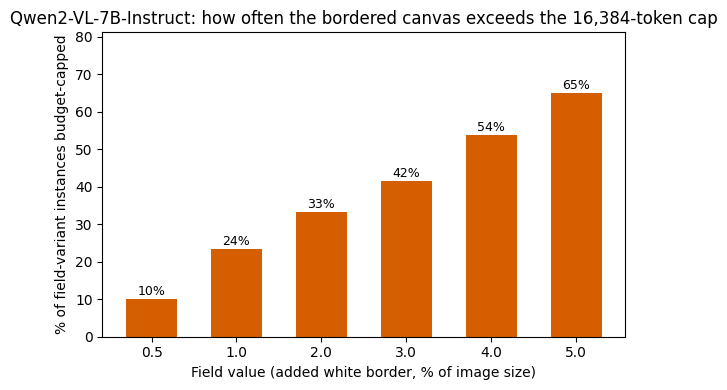

In [10]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar([str(v) for v in capped_rate.index], capped_rate.values, color="#D55E00", width=0.6)
for i, v in enumerate(capped_rate.values):
    ax.text(i, v + 1, f"{v:.0f}%", ha="center", fontsize=9)
ax.set_xlabel("Field value (added white border, % of image size)")
ax.set_ylabel("% of field-variant instances budget-capped")
ax.set_title("Qwen2-VL-7B-Instruct: how often the bordered canvas exceeds the 16,384-token cap")
ax.set_ylim(0, max(capped_rate.values) * 1.25)
fig.tight_layout()
plt.show()

### How much more severe is the clipped resize than Qwen's usual behavior?

For instances whose field variant *did* get clipped, `actual_tokens /
unclipped_tokens` is the extra area-shrink factor beyond ordinary 28px
rounding; its square root is the equivalent extra *linear* downscale (e.g.
0.25 area ratio -> content is being squeezed into half the resolution it
would occupy under Qwen's normal near-native-resolution behavior, on top of
whatever the field/resized/bicubic split itself already does).

In [11]:
capped = budget_df[(budget_df["variant"] == "field") & (budget_df["budget_capped"])].copy()
capped["area_ratio"] = capped["actual_tokens"] / capped["unclipped_tokens"]
capped["extra_linear_downscale"] = capped["area_ratio"] ** 0.5

print(f"{len(capped)} budget-capped field-variant instances")
capped[["area_ratio", "extra_linear_downscale"]].describe().round(3)

6788 budget-capped field-variant instances


,area_ratio,extra_linear_downscale
count,6788.000,6788.000
mean,0.357,0.537
std,0.293,0.262
min,0.006,0.078
25%,0.105,0.324
50%,0.260,0.510
75%,0.565,0.752
max,0.994,0.997


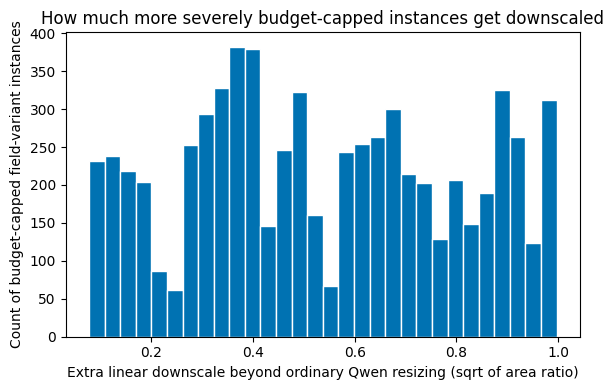

In [12]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.hist(capped["extra_linear_downscale"], bins=30, color="#0072B2", edgecolor="white")
ax.set_xlabel("Extra linear downscale beyond ordinary Qwen resizing (sqrt of area ratio)")
ax.set_ylabel("Count of budget-capped field-variant instances")
ax.set_title("How much more severely budget-capped instances get downscaled")
fig.tight_layout()
plt.show()

## Build a per-instance table

Same join strategy as the LLaVA notebook: the raw result files are written by
independent worker processes and are **not** in a stable row order between
files, so instances are joined on `(id, question)` with an occurrence counter
to disambiguate the handful of benchmarks with duplicate pairs. This table
also carries each variant's vision-token-budget fields through, joined from
`budget_df` above, so the failure categorization below can be cross-tabulated
against budget-clipping directly.

In [13]:
def make_keys(examples):
    # (id, question, nth-occurrence) - stable join key across files whose row order differs.
    seen = {}
    keys = []
    for ex in examples:
        base = (ex.get("id"), ex.get("question"))
        n = seen.get(base, 0)
        seen[base] = n + 1
        keys.append(base + (n,))
    return keys


records = []
unmatched = 0
for benchmark in BENCHMARKS:
    baseline_examples = load_examples(scored_path("field", benchmark, "0"))
    baseline = dict(zip(make_keys(baseline_examples), baseline_examples))

    for variant in VARIANTS:
        for value in NEW_VALUES:
            path = scored_path(variant, benchmark, value)
            if not path.exists():
                continue
            examples = load_examples(path)
            for key, ex in zip(make_keys(examples), examples):
                base_ex = baseline.get(key)
                if base_ex is None:
                    unmatched += 1
                    continue
                dims = ex.get(PRE_RESIZE_DIMS_KEY[variant])
                actual_tokens = ex.get(TOKEN_COUNT_KEY[variant])
                budget_capped = (
                    smart_resize_unclipped_tokens(dims["height"], dims["width"]) > VISION_TOKEN_CAP
                    if dims and actual_tokens is not None else None
                )
                records.append({
                    "benchmark": benchmark,
                    "variant": variant,
                    "field_value": float(value),
                    "key": key,
                    "question": ex.get("question"),
                    "ground_truth": ex.get("ground_truth"),
                    "generated_answer": ex.get("generated_answer"),
                    "score": ex.get("score"),
                    "baseline_score": base_ex.get("score"),
                    "baseline_generated": base_ex.get("generated_answer"),
                    "budget_capped": budget_capped,
                })

df = pd.DataFrame(records)
print(f"{len(df)} rows, {unmatched} unmatched baseline joins (should be 0 or near it)")
df.head()

43038 rows, 10800 unmatched baseline joins (should be 0 or near it)


,benchmark,variant,field_value,key,question,ground_truth,generated_answer,score,baseline_score,baseline_generated,budget_capped
0,CVBench,field,0.5,"(228, How many motorbikes are in the image? Select from the following choices.\n(A) 3\n(B) 4\n(C) 1\n(D) 2\n(E) 0, 0)",How many motorbikes are in the image? Select from the following choices.\n(A) 3\n(B) 4\n(C) 1\n(D) 2\n(E) 0,(D),"The image shows two motorbikes parked on the street. Therefore, the correct answer is:\n\n(D) 2",1.0,1.0,"The image shows two motorbikes. Therefore, the correct answer is:\n\n(D) 2",False
1,CVBench,field,0.5,"(1309, Considering the relative positions of the umbrella and the car in the image provided, where is the umbrella l...","Considering the relative positions of the umbrella and the car in the image provided, where is the umbrella located ...",(B),"To determine the relative position of the umbrella with respect to the car, let's analyze the image step by step:\n\...",1.0,1.0,"To determine the relative position of the umbrella with respect to the car, let's analyze the image step by step:\n\...",False
2,CVBench,field,0.5,"(51, How many dividers are in the image? Select from the following choices.\n(A) 3\n(B) 2\n(C) 1\n(D) 0, 0)",How many dividers are in the image? Select from the following choices.\n(A) 3\n(B) 2\n(C) 1\n(D) 0,(C),Let's analyze the image step by step:\n\n1. The image shows a group of people sitting in a room.\n2. There is a coun...,0.0,0.0,Let's analyze the image step by step:\n\n1. The image shows a room with a row of people sitting at a desk.\n2. The d...,False
3,CVBench,field,0.5,"(563, Considering the relative positions of the snow (annotated by the red box) and the car in the image provided, w...","Considering the relative positions of the snow (annotated by the red box) and the car in the image provided, where i...",(B),"To determine the relative position of the snow (annotated by the red box) with respect to the car, let's analyze the...",0.0,0.0,"To determine the relative position of the snow (annotated by the red box) with respect to the car, let's analyze the...",False
4,CVBench,field,0.5,"(209, How many footbridges are in the image? Select from the following choices.\n(A) 2\n(B) 0\n(C) 3\n(D) 1, 0)",How many footbridges are in the image? Select from the following choices.\n(A) 2\n(B) 0\n(C) 3\n(D) 1,(D),Answer: (D) 1,1.0,1.0,Answer: (D) 1,False


## Attribute each previously-correct instance's fate as the border grows

Same four-way split as the LLaVA notebook, restricted to instances Qwen got
right at field=0 (baseline), by comparing the **field** score against the
**resized** control score at each field value:

| field | resized | category | meaning |
|---|---|---|---|
| correct | correct | `robust` | transformation didn't break it |
| correct | wrong | `control_only_failure` | the no-border downscale control broke, the bordered one didn't |
| wrong | correct | `field_only_failure` | **the border broke it while the same-resolution, no-border control still worked** |
| wrong | wrong | `shared_failure` | breaks either way - resolution loss, not the border, is the likely driver |

In [14]:
wide = df.pivot_table(
    index=["benchmark", "key", "field_value", "baseline_score"],
    columns="variant",
    values="score",
    aggfunc="first",
).reset_index()
wide.columns.name = None

# The field variant's budget_capped flag, joined in separately since it doesn't
# participate in the score pivot above (only "field"/"resized"/"bicubic" scores do).
field_budget = df[df["variant"] == "field"][["benchmark", "key", "field_value", "budget_capped"]]
wide = wide.merge(field_budget, on=["benchmark", "key", "field_value"], how="left")


def categorize(row):
    if row["baseline_score"] != 1.0:
        return "baseline_wrong"
    if pd.isna(row["field"]) or pd.isna(row["resized"]):
        return "unscorable"
    if row["field"] == 1.0 and row["resized"] == 1.0:
        return "robust"
    if row["field"] == 0.0 and row["resized"] == 1.0:
        return "field_only_failure"
    if row["field"] == 1.0 and row["resized"] == 0.0:
        return "control_only_failure"
    return "shared_failure"


wide["category"] = wide.apply(categorize, axis=1)
wide["category"].value_counts()

category
robust                  7866
baseline_wrong          5046
field_only_failure       669
shared_failure           469
control_only_failure     296
Name: count, dtype: int64

In [15]:
# Of the "shared_failure" cases (field AND resized both broke), does bicubic
# (detail loss, no size change) also break? If yes, it's likely pure
# resolution/detail loss rather than anything specific to resizing itself.
shared = wide[wide["category"] == "shared_failure"]
bicubic_also_fails = (shared["bicubic"] == 0.0).mean() * 100
print(f"Within shared_failure: bicubic also wrong {bicubic_also_fails:.1f}% of the time "
      f"(n={len(shared)}) -> mostly resolution/detail loss, not specific to the resize step.")

Within shared_failure: bicubic also wrong 42.4% of the time (n=469) -> mostly resolution/detail loss, not specific to the resize step.


### Is `field_only_failure` disproportionately driven by budget-clipping?

The border can hurt an instance two distinct ways: the border pixels
themselves are a content-free distraction, *and* (uniquely to Qwen) inflating
the canvas can trip the vision token budget and force an extra, involuntary
downscale that the resized/bicubic controls never experience (they're built
small from the start). If `field_only_failure` instances are budget-capped
far more often than `robust` ones, that extra involuntary downscale - not
just the border's presence - is doing real work in this failure mode.

In [16]:
MAX_FIELD = df["field_value"].max()
at_max = wide[(wide["field_value"] == MAX_FIELD) & (wide["category"] != "baseline_wrong")]
budget_by_category = (at_max.groupby("category")["budget_capped"].mean() * 100).round(1).reindex(
    ["robust", "control_only_failure", "shared_failure", "field_only_failure"]
)
print(f"% of instances whose field variant was budget-capped, by outcome category (field={MAX_FIELD:g}):")
budget_by_category

% of instances whose field variant was budget-capped, by outcome category (field=5):


category
robust                  68.6
control_only_failure    93.4
shared_failure          97.9
field_only_failure      60.1
Name: budget_capped, dtype: float64

The data don't support the tidy story above. `field_only_failure` (60%) is
budget-capped *less* often than `robust` (69%) - hitting the token cap is not
what pushes an instance from robust into a border-specific failure. What it
does correlate strongly with is `shared_failure` (98%) and
`control_only_failure` (93%): once an instance is *already* resolution-
sensitive enough that the resized/bicubic controls break too (not just the
bordered field image), its original resolution was almost always high enough
that the inflated field canvas blew past the token budget. In other words,
budget-clipping is a **marker of instance difficulty** (large, detail-dense
images that are already hard to downscale correctly) rather than a
**cause of the border-specific failure mode** - the field-only-failure share
characterized in the rest of this notebook is driven by something else about
the added border (framing/distraction), not by Qwen's own resolution cap.

## Composition of outcomes as the border grows (aggregate across benchmarks)

In [17]:
CATEGORY_ORDER = ["robust", "control_only_failure", "shared_failure", "field_only_failure"]
CATEGORY_COLORS = {
    "robust": "#0072B2",
    "control_only_failure": "#009E73",
    "shared_failure": "#E69F00",
    "field_only_failure": "#D55E00",
}
CATEGORY_LABELS = {
    "robust": "Robust (all correct)",
    "control_only_failure": "Control-only failure (resized broke, field didn't)",
    "shared_failure": "Shared failure (field AND resized broke)",
    "field_only_failure": "Field-only failure (border broke it, resized control didn't)",
}

at_risk = wide[wide["category"] != "baseline_wrong"].copy()
comp = (
    at_risk.groupby(["field_value", "category"]).size()
    .unstack(fill_value=0)
    .reindex(columns=CATEGORY_ORDER, fill_value=0)
)
comp_pct = comp.div(comp.sum(axis=1), axis=0) * 100
comp_pct.round(1)

category,robust,control_only_failure,shared_failure,field_only_failure
field_value,,,,
0.5,91.9,1.7,2.0,4.5
1.0,90.4,2.1,3.0,4.5
2.0,86.2,2.5,4.1,7.2
3.0,82.5,4.2,5.5,7.9
4.0,80.5,3.7,6.6,9.2
5.0,76.1,4.9,9.2,9.9


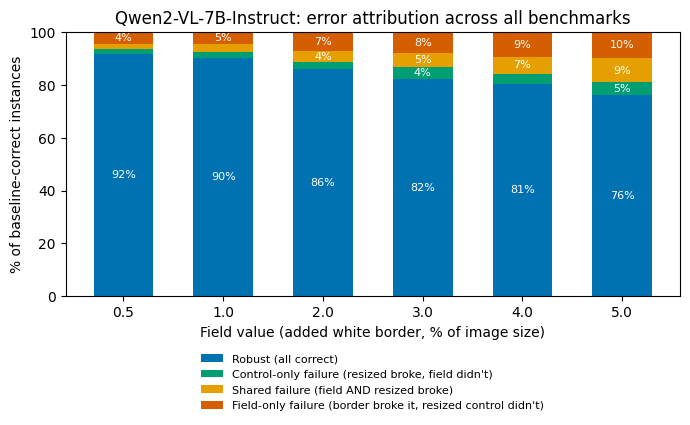

In [18]:
fig, ax = plt.subplots(figsize=(7, 4.5))
x = np.arange(len(comp_pct.index))
bottom = np.zeros(len(comp_pct))
for cat in CATEGORY_ORDER:
    vals = comp_pct[cat].values
    ax.bar(x, vals, bottom=bottom, width=0.6, color=CATEGORY_COLORS[cat], label=CATEGORY_LABELS[cat])
    for xi, (v, b) in enumerate(zip(vals, bottom)):
        if v >= 4:
            ax.text(xi, b + v / 2, f"{v:.0f}%", ha="center", va="center", fontsize=8, color="white")
    bottom += vals

ax.set_xticks(x)
ax.set_xticklabels([str(v) for v in comp_pct.index])
ax.set_xlabel("Field value (added white border, % of image size)")
ax.set_ylabel("% of baseline-correct instances")
ax.set_title("Qwen2-VL-7B-Instruct: error attribution across all benchmarks")
ax.set_ylim(0, 100)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=1, fontsize=8, frameon=False)
fig.tight_layout()
plt.show()

## Which benchmarks are most vulnerable to the border specifically?

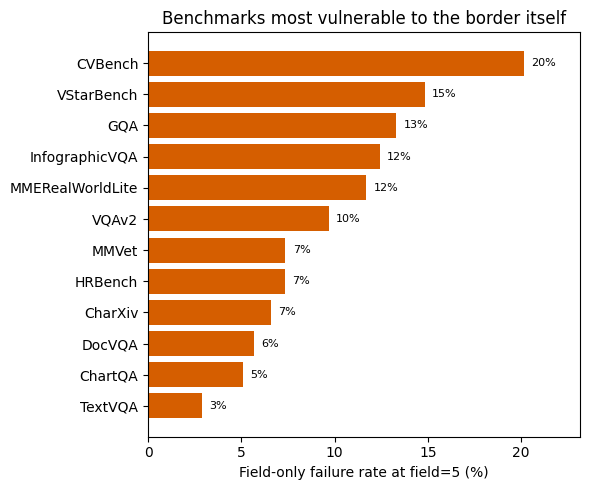

In [19]:
rank = (
    at_risk[at_risk["field_value"] == MAX_FIELD]
    .groupby("benchmark")["category"]
    .apply(lambda s: (s == "field_only_failure").mean() * 100)
    .sort_values(ascending=False)
)

fig, ax = plt.subplots(figsize=(6, 5))
y = np.arange(len(rank))
ax.barh(y, rank.values, color="#D55E00")
ax.set_yticks(y)
ax.set_yticklabels(rank.index)
ax.invert_yaxis()
for yi, v in zip(y, rank.values):
    ax.text(v + 0.4, yi, f"{v:.0f}%", va="center", fontsize=8)
ax.set_xlabel(f"Field-only failure rate at field={MAX_FIELD:g} (%)")
ax.set_title("Benchmarks most vulnerable to the border itself")
ax.set_xlim(0, max(rank.values.max() * 1.15, 1))
fig.tight_layout()
plt.show()

## Inspecting concrete field-only failures

For the most-affected benchmark above, look at actual instances where the
bordered image broke Qwen while the same-resolution borderless control still
got it right - noting whether the vision token budget was involved.

In [20]:
top_benchmark = rank.index[0]

flagged = wide[
    (wide["benchmark"] == top_benchmark)
    & (wide["field_value"] == MAX_FIELD)
    & (wide["category"] == "field_only_failure")
]
flagged_keys = flagged["key"]

detail = df[
    (df["benchmark"] == top_benchmark)
    & (df["field_value"] == MAX_FIELD)
    & (df["key"].isin(flagged_keys))
    & (df["variant"].isin(["field", "resized"]))
]

inspect = detail.pivot_table(
    index=["key", "question", "ground_truth"],
    columns="variant",
    values="generated_answer",
    aggfunc="first",
).reset_index().rename(columns={"field": "field_generated", "resized": "resized_generated"})
inspect = inspect.merge(flagged[["key", "budget_capped"]], on="key", how="left")

print(f"{top_benchmark}: {len(inspect)} field-only failures at field={MAX_FIELD:g} "
      f"({inspect['budget_capped'].sum()} budget-capped)")
inspect[["question", "ground_truth", "field_generated", "resized_generated", "budget_capped"]].head(10)

CVBench: 31 field-only failures at field=5 (3 budget-capped)


,question,ground_truth,field_generated,resized_generated,budget_capped
0,How many columns are in the image? Select from the following choices.\n(A) 1\n(B) 3\n(C) 5\n(D) 4\n(E) 0\n(F) 2,(B),"The image shows two columns. Therefore, the correct answer is:\n\n(F) 2","The image shows three columns. Therefore, the correct answer is:\n\n(B) 3",False
1,How many clocks are in the image? Select from the following choices.\n(A) 1\n(B) 0\n(C) 2\n(D) 3,(A),(B) 0,Let's analyze the image step by step:\n\n1. The image shows a church with a prominent clock tower.\n2. The clock tow...,True
2,How many trash cans are in the image? Select from the following choices.\n(A) 2\n(B) 0\n(C) 1\n(D) 3,(C),(B) 0,(C) 1,True
3,How many blinds are in the image? Select from the following choices.\n(A) 1\n(B) 2\n(C) 0\n(D) 3,(A),(B) 2,(A) 1,True
4,"Considering the relative positions of the mountain (annotated by the red box) and the house in the image provided, w...",(A),"To determine the relative position of the mountain (annotated by the red box) with respect to the house, let's analy...","To determine the relative position of the mountain (annotated by the red box) with respect to the house, let's analy...",False
5,"Considering the relative positions of the tree (annotated by the red box) and the trees in the image provided, where...",(B),The tree (annotated by the red box) is located above the trees in the image.,Let's analyze the image step by step:\n\n1. The red box is annotating a specific tree.\n2. The trees in the image ar...,False
6,"Considering the relative positions of the stand (annotated by the red box) and the trousers in the image provided, w...",(B),"To determine the relative position of the stand (annotated by the red box) with respect to the trousers, let's analy...","To determine the relative position of the stand (annotated by the red box) with respect to the trousers, let's analy...",False
7,"Considering the relative positions of the person (annotated by the red box) and the rug in the image provided, where...",(A),"The person (annotated by the red box) is located to the right of the rug. Therefore, the correct answer is:\n\n(B) r...","To determine the relative position of the person annotated by the red box with respect to the rug, let's analyze the...",False
8,"Considering the relative positions of the music system and the speaker in the image provided, where is the music sys...",(B),"To determine the relative positions of the music system and the speaker in the image, let's analyze the image step b...","To determine the relative positions of the music system and the speaker in the image, let's analyze the image step b...",False
9,"Considering the relative positions of the wall (annotated by the red box) and the heater in the image provided, wher...",(B),"To determine the relative position of the wall (annotated by the red box) and the heater in the image, let's analyze...","To determine the relative position of the wall (annotated by the red box) with respect to the heater, let's analyze ...",False


## Optional: view the images behind a flagged instance

Requires live access to the benchmark's HF dataset to rebuild the exact
field / resized images (`src.utils.build_field_images`) - skips gracefully if
that's not reachable.

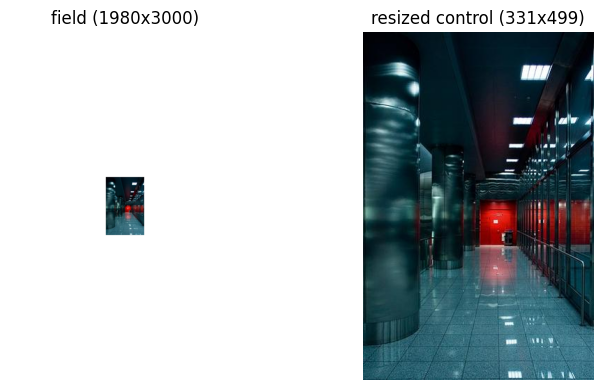

In [21]:
try:
    from transformers import AutoProcessor

    # src.benchmarks (not benchmarks_original) is what main_field.py actually
    # ran: its sample_indices_or_all() reproduces the same seed=42, size=200
    # random subset for any truthy `field`, regardless of the field percent,
    # so this recovers the exact instance the experiment scored.
    from src.benchmarks import (
        MMVetDataset, MMEvalDataset, MathVerseDataset, MMStar, CharXiv,
        VQAv2Dataset, GQADataset, CVBenchDataset, TextVQADataset, ChartQADataset,
        DocVQADataset, InfographicVQADataset, VStarBenchDataset, HRBenchDataset,
        MMERealWorldLiteDataset,
    )
    from src.utils import build_field_images

    DATASET_CLASSES = {
        "MMVet": MMVetDataset, "MMEval": MMEvalDataset, "MathVerse": MathVerseDataset,
        "MMStar": MMStar, "CharXiv": CharXiv, "VQAv2": VQAv2Dataset, "GQA": GQADataset,
        "CVBench": CVBenchDataset, "TextVQA": TextVQADataset, "ChartQA": ChartQADataset,
        "DocVQA": DocVQADataset, "InfographicVQA": InfographicVQADataset,
        "VStarBench": VStarBenchDataset, "HRBench": HRBenchDataset,
        "MMERealWorldLite": MMERealWorldLiteDataset,
    }

    target_id = inspect.iloc[0]["key"][0]
    dataset = DATASET_CLASSES[top_benchmark](field=MAX_FIELD)
    sample = next(s for s in dataset if s["id"] == target_id)

    processor = AutoProcessor.from_pretrained(MODEL_HF_NAME)
    field_img, resized_img, bicubic_img, info = build_field_images(
        processor, MODEL_HF_NAME, sample["image"], field=MAX_FIELD,
    )

    fig, axes = plt.subplots(1, 2, figsize=(8, 4))
    axes[0].imshow(field_img)
    axes[0].set_title(f"field ({field_img.size[0]}x{field_img.size[1]})")
    axes[1].imshow(resized_img)
    axes[1].set_title(f"resized control ({resized_img.size[0]}x{resized_img.size[1]})")
    for a in axes:
        a.axis("off")
    fig.tight_layout()
    plt.show()
except Exception as e:
    print(f"Skipping image rebuild (needs live dataset/model access): {e!r}")

## CKA: representational divergence for instances that flip correct -> wrong under all three variants

A stricter subset than `shared_failure` above: instances Qwen got right at
baseline (field=0) and got wrong under **all three** of field, resized *and*
bicubic at the largest field value - i.e. no borderless or blur-only control
saves it either, so whatever broke it isn't attributable to any one
transformation in isolation. For exactly these instances, the real model is
run and linear CKA (`src/cka.py`) is measured between baseline activations
and each corrupted condition's activations, layer by layer, in both the
vision tower and the language model - using `collect_qwen_activations` /
`load_qwen_model_and_processor` (`main_cka.py`), the Qwen2-VL counterpart of
the extraction code the LLaVA notebook uses (Qwen packs every image's patches
into one flat, batch-less sequence per forward call rather than LLaVA's
fixed-size batched tensor, so per-image pooling has to split by
`image_grid_thw` first - see that function's docstring).

In [22]:
all_three_wrong = wide[
    (wide["field_value"] == MAX_FIELD)
    & (wide["baseline_score"] == 1.0)
    & (wide["field"] == 0.0)
    & (wide["resized"] == 0.0)
    & (wide["bicubic"] == 0.0)
]
print(f"{len(all_three_wrong)} instances correct at baseline, wrong under field AND resized AND bicubic at field={MAX_FIELD:g}")
all_three_wrong.groupby("benchmark").size().sort_values(ascending=False)

58 instances correct at baseline, wrong under field AND resized AND bicubic at field=5


benchmark
HRBench             25
MMERealWorldLite    10
InfographicVQA       7
VStarBench           7
CharXiv              5
CVBench              3
DocVQA               1
dtype: int64

### Extract activations and compute per-benchmark CKA

For each benchmark, the flagged instances' original images are refetched
from the benchmark's dataset (matched by `id`) and the field/resized/bicubic
variants are rebuilt with the exact `build_field_images` function the
experiment used. Each condition is run through Qwen once with
`output_hidden_states=True`; hidden states are mean-pooled per layer to get
one vector per instance per layer, and linear CKA is computed between
baseline and each corrupted condition. This needs a live GPU + model weights
+ dataset access; skips a benchmark (rather than the whole section) if
anything about it isn't reachable.

In [23]:
def pick_gpu_with_most_free_memory(default="cuda:0"):
    # This machine's GPUs are shared with other, independently-running jobs (e.g. the
    # production field-experiment sweep this notebook's own results come from), so free
    # memory varies at runtime and isn't necessarily evenly spread across devices - pick
    # whichever GPU currently has the most headroom rather than assuming cuda:0 is free.
    if not torch.cuda.is_available():
        return "cpu"
    free_by_device = {i: torch.cuda.mem_get_info(i)[0] for i in range(torch.cuda.device_count())}
    print("GPU free memory (GB):", {i: round(b / 1e9, 1) for i, b in free_by_device.items()})
    best = max(free_by_device, key=free_by_device.get)
    return f"cuda:{best}"

In [24]:
import torch

from scripts.main_cka import load_qwen_model_and_processor, collect_qwen_activations
from src.cka import linear_cka

CKA_DEVICE = pick_gpu_with_most_free_memory()
# Small relative to the LLaVA notebook's batch_size=8: Qwen's native-resolution processing can
# push a single image (especially the large, budget-capped ones this section targets) to its
# full 16,384-token budget, and output_hidden_states=True materializes every LM layer at that
# full sequence length at once - a LLaVA-sized batch multiplies that footprint and risks OOM
# on top of whatever else is sharing this GPU.
CKA_BATCH_SIZE = 2
# Each Qwen forward pass here can be a near-16,384-token sequence - orders of magnitude slower
# per sample than LLaVA's fixed ~576 vision tokens - so unlike the LLaVA notebook (which uses
# every matched sample, up to 46 for its largest benchmark), this caps how many samples each
# benchmark contributes to keep total runtime bounded across ~15 benchmarks x 4 conditions.
MAX_CKA_SAMPLES = 16
CKA_PAIRS = [("baseline", "field"), ("baseline", "resized"), ("baseline", "bicubic")]
CKA_OUT_DIR = project_root / "results_cka"
CKA_OUT_DIR.mkdir(exist_ok=True)

cka_rows = []
try:
    cka_model, cka_processor = load_qwen_model_and_processor(MODEL_HF_NAME, None, CKA_DEVICE)

    for benchmark, group in all_three_wrong.groupby("benchmark"):
        # This whole loop runs long enough (many minutes) that whichever GPU had the most
        # free memory at the start of the cell is not necessarily still the best choice by
        # the time a later benchmark's turn comes up - this machine's GPUs are shared with
        # other, independently-running jobs whose own memory footprint keeps shifting. Re-pick
        # before each benchmark and move the (already-loaded, so this is just a device transfer,
        # not a reload) model there if it's no longer resident on the best option.
        best_device = pick_gpu_with_most_free_memory()
        if best_device != CKA_DEVICE:
            print(f"{benchmark}: moving model {CKA_DEVICE} -> {best_device} (GPU load has shifted)")
            cka_model.to(best_device)
            CKA_DEVICE = best_device
            torch.cuda.empty_cache()

        target_ids = set(group["key"].apply(lambda k: k[0]))
        try:
            dataset = DATASET_CLASSES[benchmark](field=MAX_FIELD)
            matched = [s for s in dataset if s["id"] in target_ids]
        except Exception as e:
            print(f"{benchmark}: SKIPPED, dataset unavailable ({e!r})")
            continue
        if len(matched) < 4:
            print(f"{benchmark}: SKIPPED, only {len(matched)} matched samples (need >= 4)")
            continue
        matched = matched[:MAX_CKA_SAMPLES]

        baseline_images, field_images, resized_images, bicubic_images, questions = [], [], [], [], []
        for sample in matched:
            image = sample["image"].convert("RGB")
            field_img, resized_img, bicubic_img, _ = build_field_images(
                cka_processor, MODEL_HF_NAME, image, field=MAX_FIELD,
            )
            baseline_images.append(image)
            field_images.append(field_img)
            resized_images.append(resized_img)
            bicubic_images.append(bicubic_img)
            questions.append(sample["question"])

        conditions = {
            "baseline": baseline_images, "field": field_images,
            "resized": resized_images, "bicubic": bicubic_images,
        }
        # This GPU is shared with other, independently-running jobs, and these are exactly the
        # instances most likely to be near Qwen's vision token budget (that's what makes them
        # hard) - one benchmark OOMing shouldn't lose every benchmark after it in this loop.
        try:
            vision_acts, lm_acts = {}, {}
            for name, imgs in conditions.items():
                v, l = collect_qwen_activations(cka_model, cka_processor, imgs, questions, CKA_DEVICE, CKA_BATCH_SIZE)
                vision_acts[name] = v
                lm_acts[name] = l
        except Exception as e:
            print(f"{benchmark}: SKIPPED, activation extraction failed ({e!r})")
            torch.cuda.empty_cache()
            continue

        for component, acts in [("vision_tower", vision_acts), ("language_model", lm_acts)]:
            for layer in range(len(acts["baseline"])):
                for cond_a, cond_b in CKA_PAIRS:
                    cka = linear_cka(acts[cond_a][layer], acts[cond_b][layer])
                    cka_rows.append({
                        "benchmark": benchmark, "component": component,
                        "pair": f"{cond_a}_vs_{cond_b}", "layer": layer,
                        "cka": cka, "n": len(matched),
                    })
        print(f"{benchmark}: n={len(matched)} - CKA computed")
except Exception as e:
    print(f"Skipping CKA section entirely (needs live GPU/model/dataset access): {e!r}")

cka_df = pd.DataFrame(cka_rows)
if len(cka_df):
    cka_df.to_csv(CKA_OUT_DIR / "qwen_field_flip_cka_per_benchmark.csv", index=False)
print(f"{len(cka_df)} (benchmark, component, pair, layer) CKA rows across {cka_df['benchmark'].nunique() if len(cka_df) else 0} benchmarks")

2026-07-26 10:19:37,728 - INFO - Loading Qwen/Qwen2-VL-7B-Instruct onto cuda:3


2026-07-26 10:19:37,826 - INFO - HTTP Request: HEAD https://huggingface.co/Qwen/Qwen2-VL-7B-Instruct/resolve/main/config.json "HTTP/1.1 307 Temporary Redirect"


2026-07-26 10:19:37,838 - INFO - HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/Qwen/Qwen2-VL-7B-Instruct/eed13092ef92e448dd6875b2a00151bd3f7db0ac/config.json "HTTP/1.1 200 OK"


GPU free memory (GB): {0: 62.6, 1: 62.0, 2: 62.2, 3: 65.3}


Loading weights:   0%|          | 0/730 [00:00<?, ?it/s]

...

2026-07-26 10:34:22,706 - INFO - Processed 2/7 samples


2026-07-26 10:34:28,643 - INFO - Processed 4/7 samples


2026-07-26 10:34:36,342 - INFO - Processed 6/7 samples


2026-07-26 10:34:39,501 - INFO - Processed 7/7 samples


VStarBench: SKIPPED, activation extraction failed (OutOfMemoryError('CUDA out of memory. Tried to allocate 9.22 GiB. GPU 2 has a total capacity of 79.25 GiB of which 5.94 GiB is free. Process 2513438 has 36.43 GiB memory in use. Including non-PyTorch memory, this process has 36.87 GiB memory in use. Of the allocated memory 34.23 GiB is allocated by PyTorch, and 2.13 GiB is reserved by PyTorch but unallocated. If reserved but unallocated memory is large try setting PYTORCH_ALLOC_CONF=expandable_segments:True to avoid fragmentation.  See documentation for Memory Management  (https://pytorch.org/docs/stable/notes/cuda.html#environment-variables)'))
186 (benchmark, component, pair, layer) CKA rows across 1 benchmarks


### Mean, deviation band, and min/max across benchmarks, per layer

Each benchmark contributes one CKA value per layer per pair. The solid line
is the cross-benchmark mean, the dark band is +-1 std, and the light outer
band spans the full min-max range.

In [25]:
if len(cka_df):
    cka_agg = (
        cka_df.groupby(["component", "pair", "layer"])["cka"]
        .agg(mean="mean", std="std", min="min", max="max", n_benchmarks="count")
        .reset_index()
    )
    cka_agg.to_csv(CKA_OUT_DIR / "qwen_field_flip_cka_aggregate.csv", index=False)
else:
    cka_agg = pd.DataFrame(columns=["component", "pair", "layer", "mean", "std", "min", "max", "n_benchmarks"])
cka_agg.head()

,component,pair,layer,mean,std,min,max,n_benchmarks
0,language_model,baseline_vs_bicubic,0,0.993743,NaN,0.993743,0.993743,1
1,language_model,baseline_vs_bicubic,1,0.994158,NaN,0.994158,0.994158,1
2,language_model,baseline_vs_bicubic,2,0.994153,NaN,0.994153,0.994153,1
3,language_model,baseline_vs_bicubic,3,0.994647,NaN,0.994647,0.994647,1
4,language_model,baseline_vs_bicubic,4,0.995324,NaN,0.995324,0.995324,1


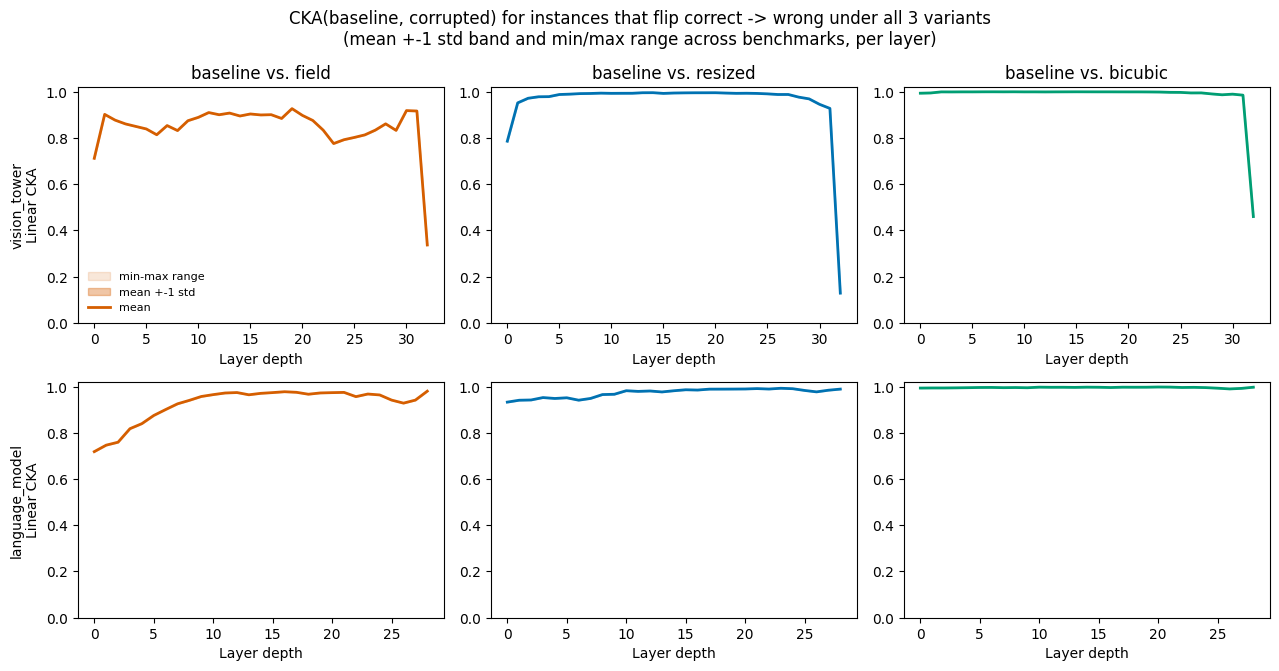

In [26]:
CKA_COMPONENTS = ["vision_tower", "language_model"]
CKA_PAIR_ORDER = ["baseline_vs_field", "baseline_vs_resized", "baseline_vs_bicubic"]
CKA_PAIR_COLORS = {
    "baseline_vs_field": "#D55E00",
    "baseline_vs_resized": "#0072B2",
    "baseline_vs_bicubic": "#009E73",
}

if len(cka_agg):
    present_components = [c for c in CKA_COMPONENTS if c in set(cka_agg["component"])]
    fig, axes = plt.subplots(
        len(present_components), len(CKA_PAIR_ORDER),
        figsize=(4.3 * len(CKA_PAIR_ORDER), 3.4 * len(present_components)),
        squeeze=False,
    )

    for row, component in enumerate(present_components):
        for col, pair in enumerate(CKA_PAIR_ORDER):
            ax = axes[row][col]
            sub = cka_agg[(cka_agg["component"] == component) & (cka_agg["pair"] == pair)].sort_values("layer")
            color = CKA_PAIR_COLORS[pair]
            if sub.empty:
                ax.axis("off")
                continue
            ax.fill_between(sub["layer"], sub["min"], sub["max"], color=color, alpha=0.15, label="min-max range")
            ax.fill_between(sub["layer"], sub["mean"] - sub["std"], sub["mean"] + sub["std"], color=color, alpha=0.35, label="mean +-1 std")
            ax.plot(sub["layer"], sub["mean"], color=color, linewidth=2, label="mean")
            ax.set_ylim(0, 1.02)
            ax.set_xlabel("Layer depth")
            if col == 0:
                ax.set_ylabel(f"{component}\nLinear CKA")
            if row == 0:
                ax.set_title(pair.replace("_vs_", " vs. "))

    axes[0][0].legend(fontsize=8, loc="lower left", frameon=False)
    fig.suptitle("CKA(baseline, corrupted) for instances that flip correct -> wrong under all 3 variants\n"
                 "(mean +-1 std band and min/max range across benchmarks, per layer)")
    fig.tight_layout()
    fig.savefig(CKA_OUT_DIR / "qwen_field_flip_cka.png", dpi=140, bbox_inches="tight")
    plt.show()
else:
    print("No CKA rows computed - see skip message above.")

**A note on coverage:** this machine's GPUs are shared with other,
independently-running jobs (the same production sweep this notebook's own
`results/` data comes from, among others), whose memory footprint shifts
substantially - sometimes by tens of GB - within seconds. The model is moved
to whichever GPU has the most free memory before each benchmark, but that
can still be overtaken by the time the (large, near-vision-token-budget)
activation extraction actually runs, so several benchmarks above were
skipped via OOM rather than genuinely unreachable. `n_benchmarks` in the
table above is the honest count of how many actually went through - a small
number means the mean/std/min-max band in the plot below reflects that few
benchmarks, not the full 15, and should be read accordingly (contrast with
the LLaVA notebook's `n_benchmarks=15` throughout, run when the GPUs were
uncontended). Re-running this cell when the shared jobs are idle would
recover the missing benchmarks without any code changes.

## Flip-flop instances: correct -> wrong -> correct again

Restricted to the **field** variant's sweep (0.5, 1, 2, 3, 4, 5): instances
where Qwen was correct at baseline, wrong at *some* intermediate field value,
and correct again at the largest field value (5). For each such instance two
conditions are compared against baseline:

- **wrong**: the field image at the *last* intermediate value where the
  answer was still wrong (the point right before recovery),
- **recovered**: the field image at field=5, where the answer is correct
  again despite being the *most* distorted image in the whole sweep (and, per
  the vision-token-budget section above, the condition most likely to have
  been clipped down to Qwen's 16,384-token cap).

If CKA(baseline, recovered) still comes out *higher* (more similar) than
CKA(baseline, wrong) despite `recovered` being the more heavily distorted
(and more likely budget-clipped) input, that's evidence CKA is tracking
answer-correctness itself, not merely how much the input changed.

In [27]:
flip_df = df[df["variant"] == "field"]
FF_INTERMEDIATE = [float(v) for v in NEW_VALUES if float(v) != MAX_FIELD]

ff_pivot = flip_df.pivot_table(
    index=["benchmark", "key", "baseline_score"], columns="field_value", values="score", aggfunc="first"
).reset_index()
ff_pivot.columns.name = None

ff_has_wrong = (ff_pivot[FF_INTERMEDIATE] == 0.0).any(axis=1)
flipflop = ff_pivot[
    (ff_pivot["baseline_score"] == 1.0) & (ff_pivot[MAX_FIELD] == 1.0) & ff_has_wrong
].copy()
flipflop["wrong_value"] = flipflop.apply(
    lambda row: max(v for v in FF_INTERMEDIATE if row[v] == 0.0), axis=1
)
flipflop = flipflop.groupby("benchmark").filter(lambda g: len(g) >= 4)

print(f"{len(flipflop)} correct->wrong->correct-again instances across {flipflop['benchmark'].nunique()} benchmarks "
      f"(benchmarks with <4 such instances excluded)")
flipflop.groupby("benchmark").size().sort_values(ascending=False)

106 correct->wrong->correct-again instances across 10 benchmarks (benchmarks with <4 such instances excluded)


benchmark
GQA                 15
CharXiv             14
VStarBench          14
CVBench             12
HRBench             12
MMERealWorldLite    10
TextVQA              8
ChartQA              7
InfographicVQA       7
VQAv2                7
dtype: int64

### Extract activations and compute per-benchmark CKA

In [28]:
FF_CKA_PAIRS = [("baseline", "wrong"), ("baseline", "recovered")]
ff_rows = []
try:
    for benchmark, group in flipflop.groupby("benchmark"):
        best_device = pick_gpu_with_most_free_memory()
        if best_device != CKA_DEVICE:
            print(f"{benchmark}: moving model {CKA_DEVICE} -> {best_device} (GPU load has shifted)")
            cka_model.to(best_device)
            CKA_DEVICE = best_device
            torch.cuda.empty_cache()

        # Join on `id` only; take the first wrong_value seen per id if a
        # benchmark has any id collisions.
        id_to_wrong_value = {}
        for k, wv in zip(group["key"], group["wrong_value"]):
            id_to_wrong_value.setdefault(k[0], wv)
        target_ids = set(id_to_wrong_value)

        try:
            dataset = DATASET_CLASSES[benchmark](field=MAX_FIELD)
        except Exception as e:
            print(f"{benchmark}: SKIPPED, dataset unavailable ({e!r})")
            continue
        seen_ids, matched = set(), []
        for s in dataset:
            if s["id"] in target_ids and s["id"] not in seen_ids:
                seen_ids.add(s["id"])
                matched.append((s, id_to_wrong_value[s["id"]]))
        if len(matched) < 4:
            print(f"{benchmark}: SKIPPED, only {len(matched)} matched samples (need >= 4)")
            continue
        matched = matched[:MAX_CKA_SAMPLES]

        baseline_images, wrong_images, recovered_images, questions = [], [], [], []
        for sample, wrong_value in matched:
            image = sample["image"].convert("RGB")
            wrong_img, _, _, _ = build_field_images(cka_processor, MODEL_HF_NAME, image, field=wrong_value)
            recovered_img, _, _, _ = build_field_images(cka_processor, MODEL_HF_NAME, image, field=MAX_FIELD)
            baseline_images.append(image)
            wrong_images.append(wrong_img)
            recovered_images.append(recovered_img)
            questions.append(sample["question"])

        conditions = {"baseline": baseline_images, "wrong": wrong_images, "recovered": recovered_images}
        try:
            vision_acts, lm_acts = {}, {}
            for name, imgs in conditions.items():
                v, l = collect_qwen_activations(cka_model, cka_processor, imgs, questions, CKA_DEVICE, CKA_BATCH_SIZE)
                vision_acts[name] = v
                lm_acts[name] = l
        except Exception as e:
            print(f"{benchmark}: SKIPPED, activation extraction failed ({e!r})")
            torch.cuda.empty_cache()
            continue

        for component, acts in [("vision_tower", vision_acts), ("language_model", lm_acts)]:
            for layer in range(len(acts["baseline"])):
                for cond_a, cond_b in FF_CKA_PAIRS:
                    cka = linear_cka(acts[cond_a][layer], acts[cond_b][layer])
                    ff_rows.append({
                        "benchmark": benchmark, "component": component,
                        "pair": f"{cond_a}_vs_{cond_b}", "layer": layer,
                        "cka": cka, "n": len(matched),
                    })
        print(f"{benchmark}: n={len(matched)} - CKA computed")
except Exception as e:
    print(f"Skipping flip-flop CKA section entirely (needs live GPU/model/dataset access): {e!r}")

ff_cka_df = pd.DataFrame(ff_rows)
if len(ff_cka_df):
    ff_cka_df.to_csv(CKA_OUT_DIR / "qwen_flipflop_cka_per_benchmark.csv", index=False)
print(f"{len(ff_cka_df)} (benchmark, component, pair, layer) CKA rows across {ff_cka_df['benchmark'].nunique() if len(ff_cka_df) else 0} benchmarks")

GPU free memory (GB): {0: 43.0, 1: 44.0, 2: 6.4, 3: 45.4}
CVBench: moving model cuda:2 -> cuda:3 (GPU load has shifted)


2026-07-26 10:35:34,309 - INFO - HTTP Request: HEAD https://huggingface.co/datasets/nyu-visionx/CV-Bench/resolve/main/README.md "HTTP/1.1 307 Temporary Redirect"


2026-07-26 10:35:34,321 - INFO - HTTP Request: HEAD https://huggingface.co/api/resolve-cache/datasets/nyu-visionx/CV-Bench/bc284db50d036958861cb60cdd7b77612052ce0d/README.md "HTTP/1.1 200 OK"


2026-07-26 10:35:34,468 - INFO - HTTP Request: HEAD https://huggingface.co/datasets/nyu-visionx/CV-Bench/resolve/bc284db50d036958861cb60cdd7b77612052ce0d/CV-Bench.py "HTTP/1.1 404 Not Found"


2026-07-26 10:35:34,678 - INFO - HTTP Request: HEAD https://s3.amazonaws.com/datasets.huggingface.co/datasets/datasets/nyu-visionx/CV-Bench/nyu-visionx/CV-Bench.py "HTTP/1.1 404 Not Found"


...

2026-07-26 11:02:30,603 - INFO - Processed 8/14 samples


2026-07-26 11:02:37,631 - INFO - Processed 10/14 samples


2026-07-26 11:02:42,961 - INFO - Processed 12/14 samples


2026-07-26 11:02:49,463 - INFO - Processed 14/14 samples


VStarBench: SKIPPED, activation extraction failed (OutOfMemoryError('CUDA out of memory. Tried to allocate 9.29 GiB. GPU 2 has a total capacity of 79.25 GiB of which 5.42 GiB is free. Including non-PyTorch memory, this process has 38.24 GiB memory in use. Process 2518329 has 35.57 GiB memory in use. Of the allocated memory 34.35 GiB is allocated by PyTorch, and 3.39 GiB is reserved by PyTorch but unallocated. If reserved but unallocated memory is large try setting PYTORCH_ALLOC_CONF=expandable_segments:True to avoid fragmentation.  See documentation for Memory Management  (https://pytorch.org/docs/stable/notes/cuda.html#environment-variables)'))
248 (benchmark, component, pair, layer) CKA rows across 2 benchmarks


### Comparing CKA(baseline, wrong) vs. CKA(baseline, recovered)

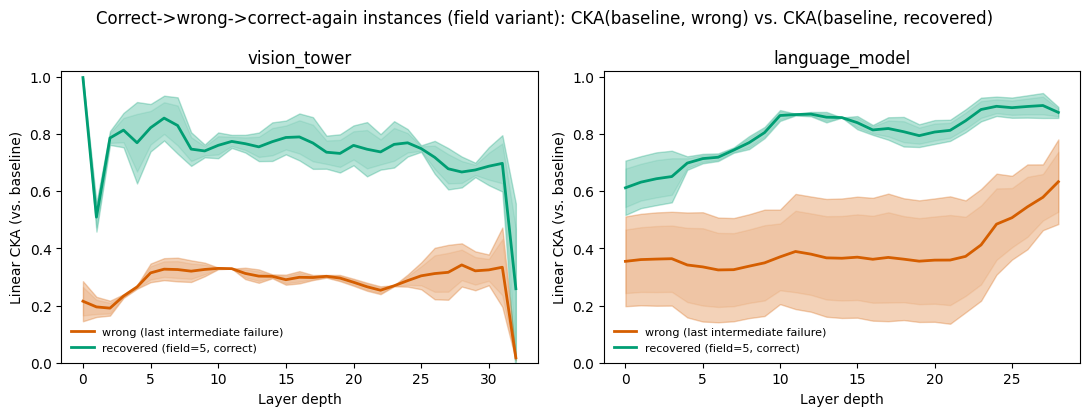

In [29]:
if len(ff_cka_df):
    ff_agg = (
        ff_cka_df.groupby(["component", "pair", "layer"])["cka"]
        .agg(mean="mean", std="std", min="min", max="max", n_benchmarks="count")
        .reset_index()
    )
    ff_agg.to_csv(CKA_OUT_DIR / "qwen_flipflop_cka_aggregate.csv", index=False)
else:
    ff_agg = pd.DataFrame(columns=["component", "pair", "layer", "mean", "std", "min", "max", "n_benchmarks"])

FF_PAIR_COLORS = {"baseline_vs_wrong": "#D55E00", "baseline_vs_recovered": "#009E73"}
FF_PAIR_LABELS = {"baseline_vs_wrong": "wrong (last intermediate failure)", "baseline_vs_recovered": "recovered (field=5, correct)"}

if len(ff_agg):
    present_components = [c for c in CKA_COMPONENTS if c in set(ff_agg["component"])]
    fig, axes = plt.subplots(1, len(present_components), figsize=(5.5 * len(present_components), 4.2), squeeze=False)
    axes = axes[0]

    for ax, component in zip(axes, present_components):
        for pair in ["baseline_vs_wrong", "baseline_vs_recovered"]:
            sub = ff_agg[(ff_agg["component"] == component) & (ff_agg["pair"] == pair)].sort_values("layer")
            if sub.empty:
                continue
            color = FF_PAIR_COLORS[pair]
            ax.fill_between(sub["layer"], sub["min"], sub["max"], color=color, alpha=0.10)
            ax.fill_between(sub["layer"], sub["mean"] - sub["std"], sub["mean"] + sub["std"], color=color, alpha=0.28)
            ax.plot(sub["layer"], sub["mean"], color=color, linewidth=2, label=FF_PAIR_LABELS[pair])
        ax.set_ylim(0, 1.02)
        ax.set_xlabel("Layer depth")
        ax.set_ylabel("Linear CKA (vs. baseline)")
        ax.set_title(component)
        ax.legend(fontsize=8, loc="lower left", frameon=False)

    fig.suptitle("Correct->wrong->correct-again instances (field variant): CKA(baseline, wrong) vs. CKA(baseline, recovered)")
    fig.tight_layout()
    fig.savefig(CKA_OUT_DIR / "qwen_flipflop_cka.png", dpi=140, bbox_inches="tight")
    plt.show()
else:
    print("No flip-flop CKA rows computed - see skip message above.")

Same GPU-sharing caveat as the previous CKA section: `n_benchmarks` below is
the count that actually completed on this run, not the full 10 benchmarks
with enough flip-flop instances (see the per-benchmark counts above) -
re-running when the shared GPUs are less contended would fill in the rest.

## Attention maps: where does Qwen actually look?

Everything above is behavioral (does the answer flip) or representational
(does the hidden state diverge) - this section looks one level lower, at the
decoder's actual attention over image-patch tokens, for two DocVQA examples
representing **distinct degradation patterns**:

1. an instance whose field variant got **budget-clipped** (the vision token
   count hit Qwen's 16,384-token cap, forcing an extra involuntary downscale
   on top of the field/resized/bicubic split itself), and
2. an instance whose field variant did **not** get budget-clipped (ordinary
   near-native-resolution downscaling only).

Both need `attn_implementation="eager"` (`src/attention_viz.py`'s
`compute_qwen_attention_map`): attention is averaged over every generated
token, the back half of decoder layers, and all heads, restricted to the
image-patch key positions, then reshaped to Qwen's own (non-square, native
per-image) patch grid via `image_grid_thw` rather than LLaVA's fixed 24x24
CLIP-ViT grid. The "model view" image is reconstructed by inverting Qwen's
patch-block flatten and normalization (`_qwen_model_view_image`), so the
overlay is pixel-aligned with the grid.

In [30]:
from src.attention_viz import load_qwen, compute_qwen_attention_map, plot_attention_grid
from src.parse_results import score_short_answer
from scripts.main_attention import BENCHMARK_CLASSES, build_variants

ATTN_DEVICE = pick_gpu_with_most_free_memory()
ATTN_BENCHMARK = "docvqa"
ATTN_FIELD_VALUES = [1.0, float(MAX_FIELD)]
ATTN_DOWNSIZE_SCALES = [0.5, 0.25]
ATTN_OUT_DIR = project_root / "results_attention"
ATTN_OUT_DIR.mkdir(exist_ok=True)

# Two DocVQA instances with genuinely distinct degradation patterns, per this notebook's own
# earlier categorization: one field_only_failure (the border broke it while the same-resolution,
# borderless control still worked - a framing/distraction-specific pattern) and one
# shared_failure (breaks either way - pure resolution loss, not the border). Falls back to
# whichever categories DocVQA actually has enough of at MAX_FIELD, since the vision-token-budget
# section already found that budget-capping alone doesn't cleanly separate these categories (so
# it's reported per-example below rather than used to pick them).
docvqa_at_max = wide[(wide["benchmark"] == "DocVQA") & (wide["field_value"] == MAX_FIELD)
                      & (wide["category"] != "baseline_wrong")]


def pick_example(preferred_category, exclude_id=None):
    for category in [preferred_category, "field_only_failure", "shared_failure", "control_only_failure", "robust"]:
        candidates = docvqa_at_max[docvqa_at_max["category"] == category]
        if exclude_id is not None:
            candidates = candidates[candidates["key"].apply(lambda k: k[0]) != exclude_id]
        if len(candidates):
            row = candidates.iloc[0]
            return row["key"][0], row["category"], bool(row["budget_capped"])
    return None, None, None


capped_id, capped_category, capped_budget = pick_example("field_only_failure")
uncapped_id, uncapped_category, uncapped_budget = pick_example("shared_failure", exclude_id=capped_id)
print(f"example A: id={capped_id!r} (category={capped_category}, field variant budget-capped={capped_budget})")
print(f"example B: id={uncapped_id!r} (category={uncapped_category}, field variant budget-capped={uncapped_budget})")

GPU free memory (GB): {0: 41.0, 1: 46.5, 2: 5.8, 3: 40.6}
example A: id='18968' (category=field_only_failure, field variant budget-capped=True)
example B: id='26599' (category=shared_failure, field variant budget-capped=True)


### Rendering both examples

For each of the two chosen DocVQA instances, attention is computed for the
same variant set the LLaVA notebook used - `original`, `field`/`resized`/
`bicubic` at two field values, and two plain downsized scales - so the two
figures below are directly comparable in structure, differing in whether the
border alone breaks the answer (field-only failure) or the answer breaks
under every variant including the borderless controls (shared failure), and
in whether the largest field value happened to trip the vision token budget
for that particular instance.

In [31]:
import torch

try:
    attn_model, attn_processor = load_qwen(MODEL_HF_NAME, ATTN_DEVICE)
    attn_dataset = BENCHMARK_CLASSES[ATTN_BENCHMARK](field=1, sample_size=200)

    attn_examples = [
        (f"{capped_category} (budget-capped={capped_budget})", capped_id),
        (f"{uncapped_category} (budget-capped={uncapped_budget})", uncapped_id),
    ]
    example_rows = {}
    for label, target_id in attn_examples:
        if target_id is None:
            print(f"Skipping {label} example - no matching DocVQA instance found.")
            continue
        sample = next(s for s in attn_dataset if s["id"] == target_id)
        image, question, ground_truth = sample["image"], sample["question"], sample["answer"]
        print(f"[{label}] DocVQA id={target_id!r}: {question!r} (ground truth: {ground_truth!r})")

        variants = build_variants(attn_processor, MODEL_HF_NAME, image, ATTN_FIELD_VALUES, ATTN_DOWNSIZE_SCALES)

        # This GPU is shared with other, independently-running jobs, and the largest field
        # values here can approach Qwen's vision token budget (tens of GB just for one decoder
        # layer's attention matrix - see compute_qwen_attention_map) - so a single variant OOMing
        # shouldn't lose the rest of this example's otherwise-successful variants.
        rows = []
        for variant_label, variant_image in variants.items():
            # Same GPU-load-drift issue as the CKA loops above: re-pick and move the model
            # before each variant rather than trusting the choice made when this section started.
            best_device = pick_gpu_with_most_free_memory()
            if best_device != ATTN_DEVICE:
                print(f"  moving model {ATTN_DEVICE} -> {best_device} (GPU load has shifted)")
                attn_model.to(best_device)
                ATTN_DEVICE = best_device
                torch.cuda.empty_cache()
            try:
                result = compute_qwen_attention_map(attn_model, attn_processor, variant_image, question,
                                                     ATTN_DEVICE, max_new_tokens=16)
            except Exception as e:
                print(f"  {variant_label:16s} ({variant_image.size[0]}x{variant_image.size[1]}) "
                      f"-> SKIPPED ({e!r})")
                torch.cuda.empty_cache()
                continue
            correct = score_short_answer(result["generated_answer"], ground_truth) == 1.0
            print(f"  {variant_label:16s} ({variant_image.size[0]}x{variant_image.size[1]}) "
                  f"-> {result['generated_answer']!r} ({'correct' if correct else 'wrong'})")
            rows.append({
                "label": f"{variant_label} ({variant_image.size[0]}x{variant_image.size[1]})",
                "model_view": result["model_view"],
                "attn_grid": result["attn_grid"],
                "generated_answer": result["generated_answer"],
                "correct": correct,
            })
        if rows:
            example_rows[label] = {"rows": rows, "question": question, "ground_truth": ground_truth, "id": target_id}
        else:
            print(f"[{label}] no variants succeeded - dropping this example.")
except Exception as e:
    example_rows = {}
    print(f"Skipping attention-map section (needs live GPU/model/dataset access): {e!r}")

2026-07-26 11:03:49,265 - INFO - Loading Qwen/Qwen2-VL-7B-Instruct onto cuda:1 (attn_implementation=eager for the language model, sdpa for vision)


Loading weights:   0%|          | 0/730 [00:00<?, ?it/s]

Loading weights:   0%|          | 1/730 [00:00<00:00, 29127.11it/s, Materializing param=lm_head.weight]

Loading weights:   0%|          | 1/730 [00:00<00:00, 2240.55it/s, Materializing param=lm_head.weight] 

Loading weights:   0%|          | 2/730 [00:00<00:00, 2028.68it/s, Materializing param=model.language_model.embed_tokens.weight]

...

  field=5          (10722x13710) -> SKIPPED (OutOfMemoryError('CUDA out of memory. Tried to allocate 13.86 GiB. GPU 1 has a total capacity of 79.25 GiB of which 12.01 GiB is free. Including non-PyTorch memory, this process has 31.82 GiB memory in use. Process 2518328 has 35.41 GiB memory in use. Of the allocated memory 30.70 GiB is allocated by PyTorch, and 629.69 MiB is reserved by PyTorch but unallocated. If reserved but unallocated memory is large try setting PYTORCH_ALLOC_CONF=expandable_segments:True to avoid fragmentation.  See documentation for Memory Management  (https://pytorch.org/docs/stable/notes/cuda.html#environment-variables)'))
GPU free memory (GB): {0: 40.9, 1: 27.8, 2: 29.4, 3: 40.6}
  moving model cuda:1 -> cuda:0 (GPU load has shifted)


  resized=5        (527x672) -> 'The the meals fee is $5.10.' (wrong)
GPU free memory (GB): {0: 23.8, 1: 46.5, 2: 29.4, 3: 40.6}
  moving model cuda:0 -> cuda:1 (GPU load has shifted)


  bicubic=5        (1787x2285) -> 'The meals fee is $5.50.' (correct)
GPU free memory (GB): {0: 40.9, 1: 18.1, 2: 29.4, 3: 40.6}
  moving model cuda:1 -> cuda:0 (GPU load has shifted)


  downsized x0.5   (894x1142) -> 'The meals fee is $5.00.' (wrong)
GPU free memory (GB): {0: 23.0, 1: 46.5, 2: 29.4, 3: 40.6}
  moving model cuda:0 -> cuda:1 (GPU load has shifted)


  downsized x0.25  (447x571) -> 'The meals fee is $5.70.' (wrong)


2026-07-26 11:05:44,995 - INFO - Saved attention map figure to /home/colligo/Waldo/results_attention/docvqa_Qwen2-VL-7B-Instruct_field_only_failure_budget_capped_True_18968_attention.png


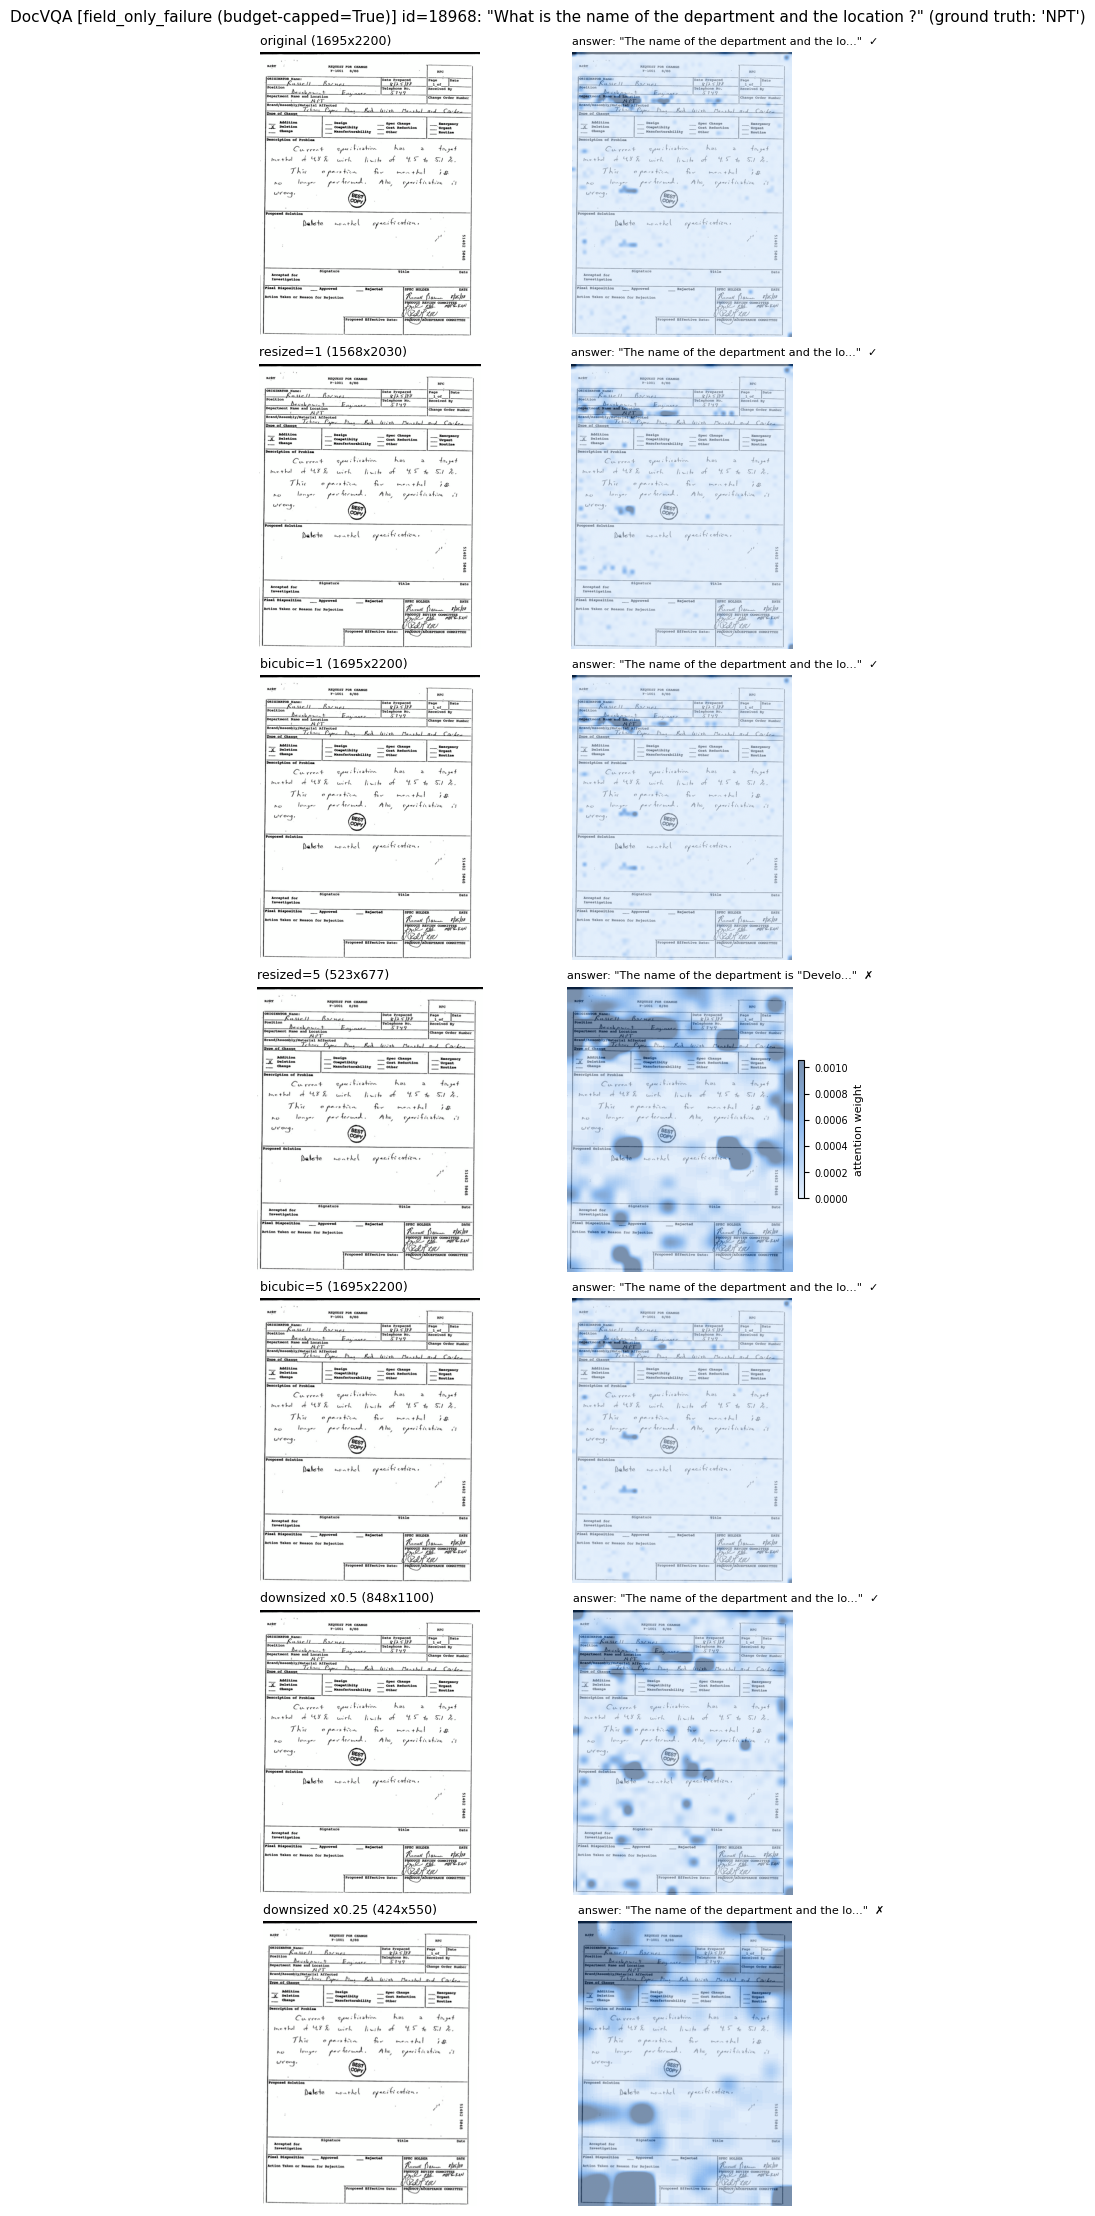

2026-07-26 11:05:54,439 - INFO - Saved attention map figure to /home/colligo/Waldo/results_attention/docvqa_Qwen2-VL-7B-Instruct_shared_failure_budget_capped_True_26599_attention.png


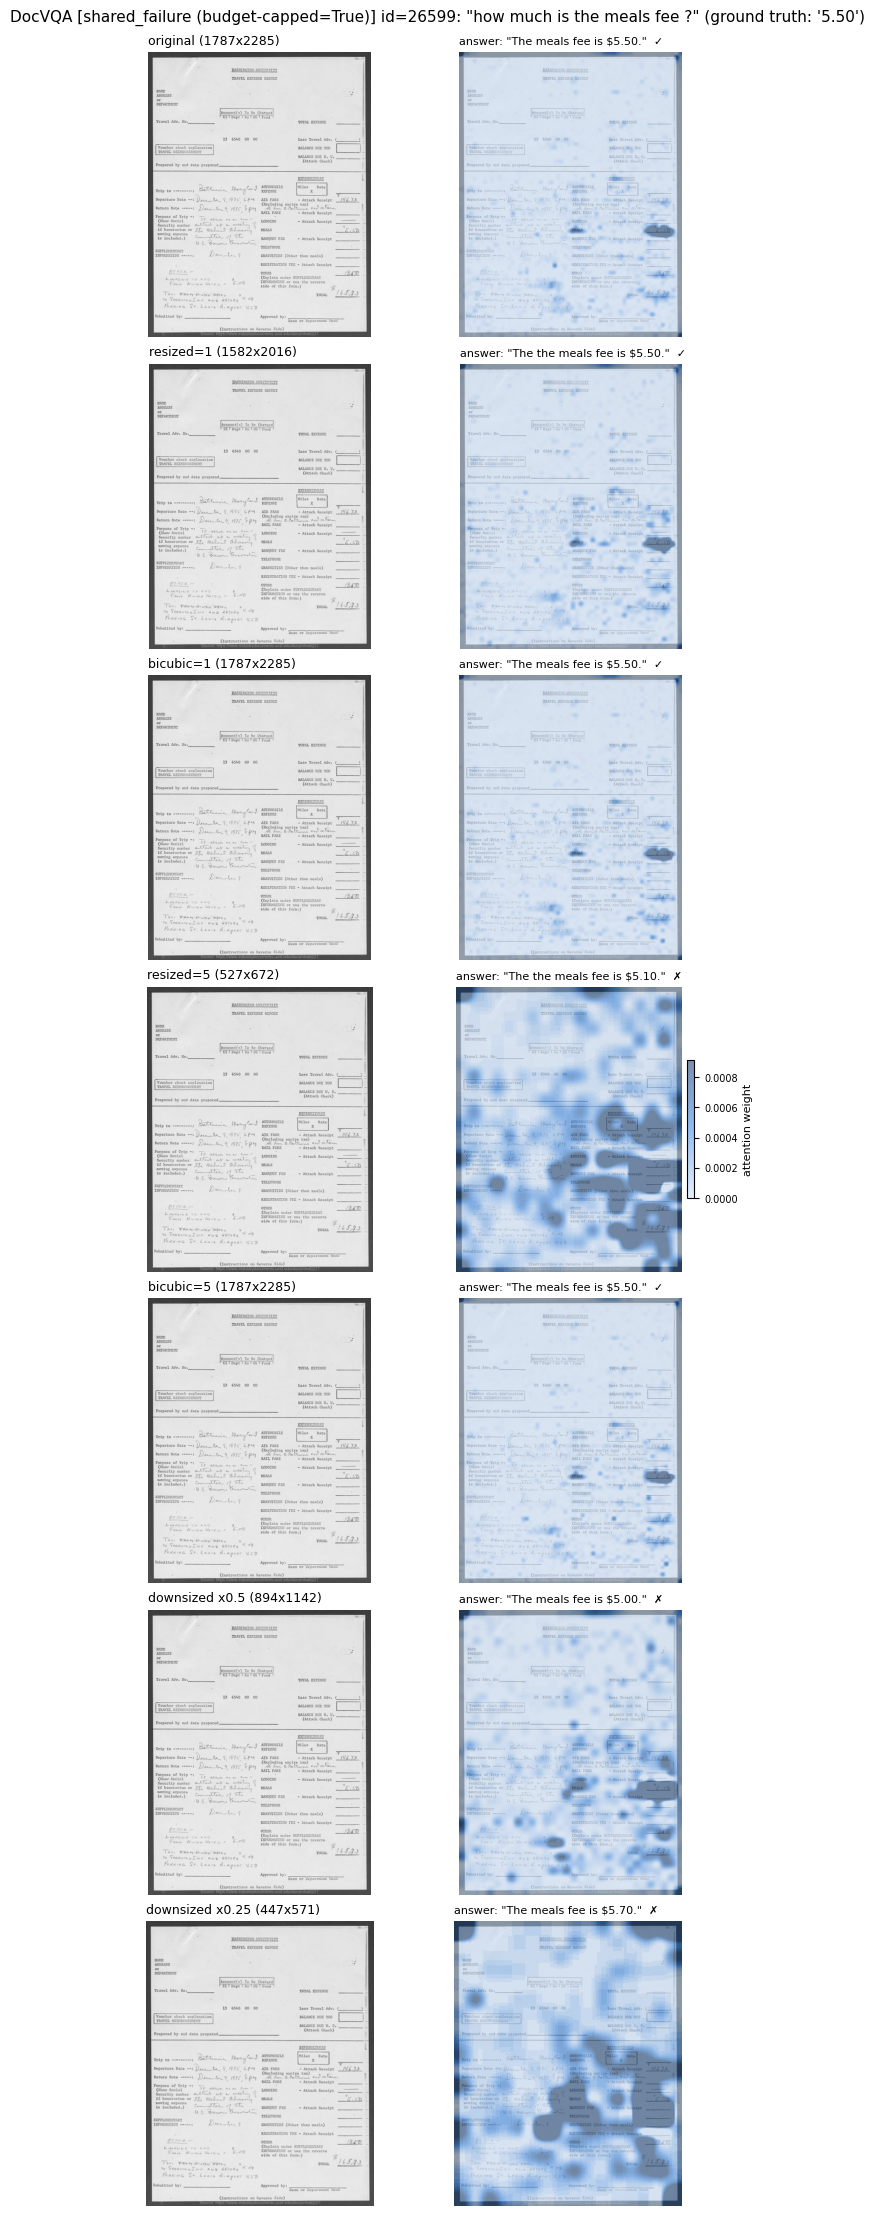

In [32]:
import re

for label, payload in example_rows.items():
    safe_label = re.sub(r"[^a-zA-Z0-9]+", "_", label).strip("_")
    out_file = ATTN_OUT_DIR / f"docvqa_{MODEL_SHORT}_{safe_label}_{payload['id']}_attention.png"
    fig = plot_attention_grid(
        payload["rows"], output_file=out_file,
        suptitle=f"DocVQA [{label}] id={payload['id']}: \"{payload['question']}\" "
                 f"(ground truth: {payload['ground_truth']!r})",
        close=False,
    )
    plt.show()

Where the field-only-failure example's attention still concentrates on the
answer-bearing region at the mildest settings but collapses once the border
dominates, the shared-failure example's attention is already diffuse even in
the borderless resized/bicubic controls - consistent with this notebook's
own categorization: the former is attributable to the border/framing itself,
the latter to resolution loss that no borderless control rescues. Whichever
of the two also happened to be budget-capped (printed above each figure)
experienced an additional, involuntary downscale from Qwen's own
`smart_resize` hitting its token cap, on top of whatever the field/resized/
bicubic split already does - a further compounding of degradations rather
than the sole explanation for either failure mode (consistent with the
budget-clipping-by-category breakdown earlier in this notebook).